# MLM representation sensitivity

Run `4_cell_line_gsea_mlm_concordance.ipynb` first: this notebook loads
the primary full-gene MLM scores from that notebook.

The primary view uses the full Hallmark gene universe on log-normalized
expression. This notebook asks whether cell line / subpopulation concordance
survives two stricter representations:

- the same 3,000 model HVGs with log-normalized expression (`hvg_uncorrected`);
- the same HVGs with scANVI-corrected normalized expression (`hvg_corrected`).

The full-gene MLM has 50 Hallmark pathways. The 3,000-HVG network retains 45
at `tmin=15`; all paired comparisons use the 45-pathway intersection so the
profiles have equal length. Notebook 7 later drops the four shared
proliferation terms to 41 for the no-proliferation comparison.
All runs use the same cells, network, `tmin=15`, and `raw=False`.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import matching, mlm, plots, signatures
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

K_MATCHING = int(bio.get("matching", {}).get("k", 50))
MARGIN = float(bio.get("matching", {}).get("margin", 0.10))
MLM = bio.get("mlm", {})
TMIN = int(MLM.get("tmin", 15))
RAW = bool(MLM.get("raw", False))
SEED = 0
FORCE_RECOMPUTE = False

## Inputs, matching groups, and HVG Hallmark network

The artifact supplies the cells, latent matching, and 3,000-HVG mask. The
sensitivity caches (corrected expression and HVG MLM scores) live next to
the primary MLM artifact under `de_dir/hallmark_mlm_sensitivity/`; derived
tables stay in memory.

In [2]:
combined = ad.read_h5ad(ROOT / paths["bio"]["joint_artifact"])
settings = combined.uns["bio_leiden_settings"]
approach = settings["approach"]
config_id = int(settings["config_id"])
num_hvg = int(settings["num_hvg"])
tumor_res = float(settings["tumor_res"])
tumor_key = f"tumor_leiden_res{tumor_res}"

de_dir = ROOT / paths["bio"]["de_joint"]
sens_dir = de_dir / "hallmark_mlm_sensitivity"
sens_dir.mkdir(parents=True, exist_ok=True)

group = matching.make_match_groups(combined.obs, tumor_key)
combined.obs["match_group"] = group
_, line_matches, _, tumor_order = matching.match_lines(
    combined.obsm["X_latent"], group, combined.obs, K_MATCHING, margin=MARGIN
)
line_order = matching.line_order(line_matches)
line_matches = line_matches.loc[line_order]

hallmark_sets = signatures.read_gmt(ROOT / paths["bio"]["hallmark_gmt"])
hvg_mask = combined.var["hvg"].astype(bool)
net_info = mlm.hvg_network_summary(
    hallmark_sets,
    combined.var_names,
    combined.var_names[hvg_mask],
    tmin=TMIN,
)
hvg_hallmark_genes = net_info["hvg_hallmark_genes"]
network_hvg = net_info["network_hvg"]
hvg_pathways = net_info["hvg_pathways"]

print(f"Hallmark genes in artifact: {len(net_info['hallmark_all_genes'])}")
print(f"Hallmark genes in 3,000-HVG set: {len(hvg_hallmark_genes)}")
print(f"Pathways retained at tmin={TMIN}: {len(hvg_pathways)}")
print(f"Pathways below tmin={TMIN} on HVG set: {net_info['dropped_pathways']}")
net_info["dropped_sizes"]

Hallmark genes in artifact: 4237
Hallmark genes in 3,000-HVG set: 1135
Pathways retained at tmin=15: 45
Pathways below tmin=15 on HVG set: ['HEDGEHOG_SIGNALING', 'MYC_TARGETS_V2', 'NOTCH_SIGNALING', 'PROTEIN_SECRETION', 'WNT_BETA_CATENIN_SIGNALING']


source
HEDGEHOG_SIGNALING             8
MYC_TARGETS_V2                 5
NOTCH_SIGNALING                3
PROTEIN_SECRETION             14
WNT_BETA_CATENIN_SIGNALING    10
Name: genes_in_hvg_set, dtype: int64

## Corrected expression cache

The corrected representation is the scANVI posterior mean with library size
10,000 (`log1p`), restricted to the Hallmark genes of the 3,000-HVG set. No
`transform_batch` is used because the cell line batch is confounded with
cell line identity.

In [3]:
run_dir = ROOT / paths["hpo"]["runs"] / f"hvg{num_hvg}" / f"config_{config_id:02d}" / approach
corrected_path = sens_dir / "scanvi_normalized_expression_hvg_hallmark.h5ad"
corrected_expression, built_corr = mlm.load_or_build_corrected_expression(
    combined,
    hvg_mask,
    hvg_hallmark_genes,
    run_dir,
    approach,
    corrected_path,
    library_size=int(MLM.get("library_size", 10000)),
    seed=SEED,
    force=FORCE_RECOMPUTE,
)
print(f"{corrected_path.relative_to(ROOT)}: {'rebuilt' if built_corr else 'cached'}")
corrected_expression

models/validation/bio_joint_cfg10/de_signatures/hallmark_mlm_sensitivity/scanvi_normalized_expression_hvg_hallmark.h5ad: cached


AnnData object with n_obs × n_vars = 110293 × 1135
    obs: 'dataset', 'cell_line', 'match_group'
    uns: 'mlm_sensitivity_manifest'

## MLM runs

The full-gene run is the primary artifact from notebook 4. The two HVG runs
are scored here and cached independently; a missing score only triggers that
representation to be recomputed.

In [4]:
REPRESENTATION_LABELS = ["hvg_corrected", "hvg_uncorrected", "full_uncorrected"]
primary_mlm = de_dir / "hallmark_mlm" / "hallmark_mlm_scores.h5ad"
assert primary_mlm.exists(), (
    f"Run 4_cell_line_gsea_mlm_concordance.ipynb first: {primary_mlm}"
)
score_paths = {
    "hvg_corrected": sens_dir / "mlm_scores_hvg_corrected.h5ad",
    "hvg_uncorrected": sens_dir / "mlm_scores_hvg_uncorrected.h5ad",
    "full_uncorrected": primary_mlm,
}


def score_representation(label, adata_expr, network):
    scores, padj = mlm.score_cells(adata_expr, network, tmin=TMIN, raw=RAW)
    obs = adata_expr.obs.loc[scores.index, ["dataset", "cell_line", "match_group"]].copy()
    mlm.save_scores(
        score_paths[label],
        scores,
        padj,
        obs,
        tmin=TMIN,
        raw=RAW,
        extra={
            "representation": label,
            "n_genes": int(adata_expr.n_vars),
            "genes": list(map(str, adata_expr.var_names)),
        },
        manifest_name=f"manifest_{label}.json",
    )


hvg_uncorrected = combined[:, hvg_hallmark_genes].copy()
hvg_uncorrected.obs["match_group"] = group.loc[hvg_uncorrected.obs_names].astype(str)

for label, adata_expr in (
    ("hvg_corrected", corrected_expression),
    ("hvg_uncorrected", hvg_uncorrected),
):
    if FORCE_RECOMPUTE or not score_paths[label].exists():
        print(f"scoring {label}")
        score_representation(label, adata_expr, network_hvg)
    else:
        print(f"using cached {label} score artifact")


using cached hvg_corrected score artifact
using cached hvg_uncorrected score artifact


In [5]:
scores_by_representation = {}
obs_by_representation = {}
n_genes_by_representation = {}
for label, path in score_paths.items():
    scores, obs, artifact = mlm.load_scores(path)
    scores_by_representation[label] = scores
    obs_by_representation[label] = obs
    n_genes_by_representation[label] = int(artifact.uns["mlm_manifest"]["n_genes"])
    print(f"{label}: {scores.shape[0]} cells x {scores.shape[1]} pathways ({n_genes_by_representation[label]} genes)")

# The full MLM has 50 pathways; the HVG network retains 45. Intersect all
# representations so every paired comparison uses equal-length profiles.
shared_pathways = sorted(
    set.intersection(*(set(scores.columns) for scores in scores_by_representation.values()))
)
for label in REPRESENTATION_LABELS:
    scores_by_representation[label] = scores_by_representation[label][shared_pathways]
print(f"shared pathways for paired comparison: {len(shared_pathways)}")


hvg_corrected: 110293 cells x 45 pathways (1135 genes)


hvg_uncorrected: 110293 cells x 45 pathways (1135 genes)


full_uncorrected: 110293 cells x 50 pathways (4237 genes)
shared pathways for paired comparison: 45


## Domain shift across representations

The domain shift is the cell line minus tumor median per pathway. Rank
correlation and the heatmap show whether the broad shift is preserved across
representations.

,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.885,0.724
hvg_uncorrected,0.885,1.000,0.647
full_uncorrected,0.724,0.647,1.000


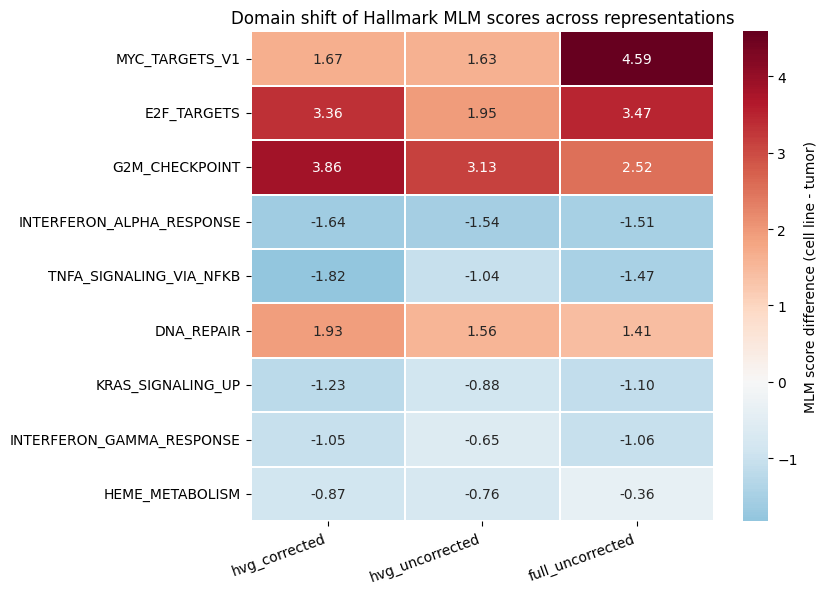

In [6]:
domain_shift = {}
for label in REPRESENTATION_LABELS:
    domain_shift[label] = mlm.domain_shift(
        scores_by_representation[label], obs_by_representation[label]
    )

shift_wide = pd.concat(
    {label: domain_shift[label]["difference"] for label in REPRESENTATION_LABELS},
    axis=1,
)
shift_corr = shift_wide.corr(method="spearman")
display(shift_corr.round(3))

plots.plot_domain_shift_representations(
    shift_wide,
    domain_shift,
    path=FIG_DIR / "mlm_domain_shift_representations.png",
)
plt.show()


## Concordance across representations

The concordance matrix is the Spearman correlation of median pathway profiles
for each cell line and tumor subpopulation. All matrices use the same 45
shared pathways, so the correlation vectors have equal length.

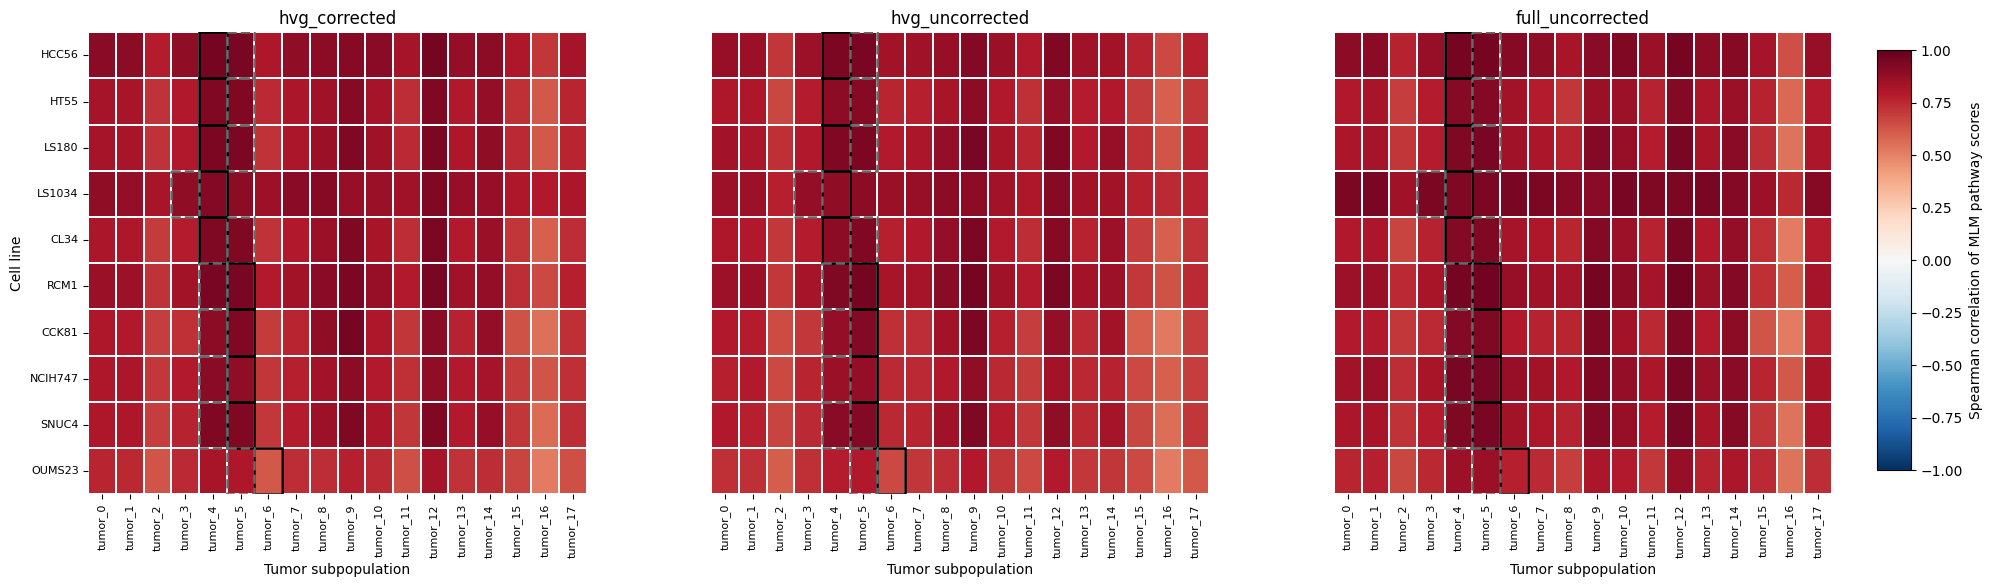

In [7]:
concordance_by_rep = {}
for label in REPRESENTATION_LABELS:
    matrix = mlm.concordance_matrix(
        scores_by_representation[label],
        obs_by_representation[label],
        line_order,
        tumor_order,
        pathways=shared_pathways,
    )
    concordance_by_rep[label] = matrix

plots.plot_concordance_representations(
    concordance_by_rep,
    line_matches,
    path=FIG_DIR / "mlm_concordance_representations.png",
)
plt.show()


In [8]:
concordance_metrics, concordance_summary = mlm.concordance_metrics_by_representation(
    concordance_by_rep, line_matches, line_order, REPRESENTATION_LABELS
)
display(concordance_summary.round(3))

print("Cross-representation Spearman correlation of the 10 x 18 concordance matrices:")
display(mlm.cross_representation_correlations(concordance_by_rep).round(3))


,n_lines,n_primary_gt_runner_up,median_primary_rho,min_primary_rho,median_runner_up_rho,median_primary_minus_runner_up,n_primary_top1,median_primary_rank
representation,,,,,,,,
hvg_corrected,10,7,0.928,0.620,0.924,0.004,3,2.0
hvg_uncorrected,10,5,0.906,0.662,0.903,0.004,0,2.0
full_uncorrected,10,3,0.936,0.779,0.938,-0.004,3,3.0


Cross-representation Spearman correlation of the 10 x 18 concordance matrices:


,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.966,0.856
hvg_uncorrected,0.966,1.000,0.843
full_uncorrected,0.856,0.843,1.000


## MLM and GSEA consistency

The tumor-side MLM contrast is compared with the signed GSEA NES for each
representation.

In [9]:
gsea_tumor = pd.read_csv(de_dir / "gsea_hallmark" / "hallmark_prerank_tumor.csv")
consistency_rows = []
for label in REPRESENTATION_LABELS:
    comp, directional, rho = mlm.mlm_gsea_consistency(
        scores_by_representation[label],
        obs_by_representation[label],
        gsea_tumor,
        tumor_order,
    )
    consistency_rows.append(
        {
            "representation": label,
            "n_comparisons": len(comp),
            "directional_agreement": directional,
            "spearman": rho,
        }
    )
consistency = pd.DataFrame(consistency_rows).set_index("representation")
consistency.round(3)


,n_comparisons,directional_agreement,spearman
representation,,,
hvg_corrected,810,0.728,0.642
hvg_uncorrected,810,0.680,0.517
full_uncorrected,810,0.683,0.496


## Summary

The summary compares gene coverage, rank stability, and primary-minus-runner-up
behavior across representations.

In [10]:
summary_rows = []
for label in REPRESENTATION_LABELS:
    matrix = concordance_by_rep[label]
    values = matrix.to_numpy(dtype=float)
    metrics = concordance_metrics.loc[concordance_metrics["representation"].eq(label)]
    summary_rows.append(
        {
            "representation": label,
            "n_genes": n_genes_by_representation[label],
            "n_pathways": len(shared_pathways),
            "shift_spearman_vs_full": float(shift_corr.loc[label, "full_uncorrected"]),
            "min_line_subpop_rho": float(np.nanmin(values)),
            "median_line_subpop_rho": float(np.nanmedian(values)),
            "n_lines_primary_gt_runner_up": int(
                (metrics["primary_minus_runner_up"] > 0).sum()
            ),
            "median_primary_minus_runner_up": float(
                metrics["primary_minus_runner_up"].median()
            ),
            "mlm_gsea_directional_agreement": float(
                consistency.loc[label, "directional_agreement"]
            ),
            "mlm_gsea_spearman": float(consistency.loc[label, "spearman"]),
        }
    )
summary = pd.DataFrame(summary_rows).set_index("representation")
summary.to_csv(sens_dir / "summary_representations.csv")
summary.round(3)

,n_genes,n_pathways,shift_spearman_vs_full,min_line_subpop_rho,median_line_subpop_rho,n_lines_primary_gt_runner_up,median_primary_minus_runner_up,mlm_gsea_directional_agreement,mlm_gsea_spearman
representation,,,,,,,,,
hvg_corrected,1135,45,0.724,0.519,0.816,7,0.004,0.728,0.642
hvg_uncorrected,1135,45,0.647,0.521,0.798,5,0.004,0.680,0.517
full_uncorrected,4237,45,1.000,0.516,0.834,3,-0.004,0.683,0.496
